# In-Context Learning, Part 1a: Watch a Transformer Learn to Learn

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/nathanmaulding/tutorial-projects/blob/main/in-context-learning/01_icl_inside_a_transformer.ipynb)

Show a large language model three examples of a pattern it has never seen, and it continues the pattern. Its weights don't change; it "learns" from the prompt alone. This is **in-context learning (ICL)**, and it's one of the most surprising things transformers do.

ICL is easiest to understand in a setting small enough to build yourself. We'll train a 150,000-parameter transformer whose every prompt is a handful of (x, y) pairs from a *new* random linear function, and whose job is to predict y for the next x. Then we'll ask: what algorithm did it learn? Does it match the textbook answer? And where does it break?

**What you'll learn**

1. What in-context learning is, and how it differs from training
2. How to set up a family of tasks so a model must learn *from the prompt*
3. A transformer small enough to read in one screen
4. Comparing the model with known algorithms: least squares, one step of gradient descent, nearest neighbour
5. Testing that it really uses the examples (scramble them and watch it fail)
6. Where in-context learning breaks: inputs unlike its training

**Runtime:** about 1 minute using the saved model; about 8 minutes on a laptop CPU if you retrain it. No GPU, no API key.

> 🎬 *Video walkthrough: coming soon.*

*Based on Garg, Tsipras, Liang and Valiant (2022), "What can transformers learn in-context? A case study of simple function classes", and von Oswald et al. (2023), "Transformers learn in-context by gradient descent".*

## 0. Setup

In [1]:
import os, sys, time
if "google.colab" in sys.modules and not os.path.exists("icl_llm"):
    !git clone -q --depth 1 https://github.com/nathanmaulding/tutorial-projects.git
    %cd tutorial-projects/in-context-learning

from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

torch.manual_seed(0); np.random.seed(0)
torch.set_num_threads(4)
plt.rcParams.update({"figure.figsize": (7.5, 4.3), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 11})
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
CKPT = Path("models/tiny_icl.pt")
RETRAIN = False          # set True to train from scratch (about 8 minutes on a laptop CPU)

## 1. Learning without changing any weights

Ordinary machine learning has two phases. **Training** adjusts the weights to fit data; **inference** uses the frozen weights. In-context learning blurs this: at inference time the prompt contains examples of a *new* task, and the model performs that task without any weight update.

How can a fixed function learn? Because it was trained on *many* tasks, each presented as a prompt of examples. The only way to do well across all of them is to read the examples in the prompt and infer the task. Training doesn't teach it one function; it teaches it **a procedure for learning functions from examples**. That procedure lives in the weights and runs during the forward pass.

| | Training | In-context learning |
|---|---|---|
| what changes | the weights | nothing: the examples sit in the prompt |
| where the "learning" happens | the optimiser | the forward pass |
| cost of a new task | a training run | a longer prompt |

## 2. A family of tasks

Each prompt comes from a fresh random linear function in 5 dimensions:

$$ y = w \cdot x, \qquad w \sim \mathcal{N}(0, I_5), \qquad x \sim \mathcal{N}(0, I_5) $$

The model sees $(x_1, y_1), (x_2, y_2), \ldots, (x_k, y_k)$ and must predict $y_{k+1}$ from $x_{k+1}$. Because $w$ is new every time, memorising is useless: the only route to a low error is working out $w$ from the examples.

In [2]:
D, K = 5, 20     # input dimension, examples per prompt

def sample(batch, k=K, d=D, x_scale=1.0):
    w = torch.randn(batch, d, 1)                    # a new linear function per prompt
    x = torch.randn(batch, k + 1, d) * x_scale
    y = (x @ w).squeeze(-1)
    return x, y

x, y = sample(1, k=3)
for i in range(3):
    print(f"x_{i+1} = {np.round(x[0, i].numpy(), 2)}   y_{i+1} = {y[0, i].item():6.2f}")
print(f"x_4 = {np.round(x[0, 3].numpy(), 2)}   y_4 = ?   (true answer {y[0, 3].item():.2f})")

x_1 = [-0.09  0.52 -0.67  0.85 -0.61]   y_1 =   2.31
x_2 = [ 0.03 -0.49  0.25  0.44  0.11]   y_2 =  -0.22
x_3 = [ 0.64  0.44 -0.1   0.79 -0.29]   y_3 =   1.85
x_4 = [ 0.05  0.52  2.3  -1.47 -1.59]   y_4 = ?   (true answer -4.20)


> ⏸️ **Pause and predict:** with $w$ in 5 dimensions, how many examples does a perfect learner need before it can predict $y$ *exactly*? What should its error look like with fewer than that?

## 3. A transformer you can read in one screen

The prompt becomes a sequence of tokens that alternate $x_1, y_1, x_2, y_2, \ldots$. Each token is a 6-number vector: an $x$ token is $[x, 0]$ and a $y$ token is $[0, \ldots, 0, y]$. A **causal mask** lets each position see only earlier tokens, so the prediction at the token $x_{i}$ can use every example before it, and nothing after. We read the model's output at every $x$ token, which means one prompt trains it at every prompt length from 0 to 20 at once.

In [3]:
class TinyGPT(nn.Module):
    def __init__(self, d=D, width=64, layers=3, heads=4, max_len=2 * (K + 1)):
        super().__init__()
        self.read_in = nn.Linear(d + 1, width)
        self.pos = nn.Parameter(torch.zeros(1, max_len, width))          # learned positions
        layer = nn.TransformerEncoderLayer(width, heads, 4 * width, dropout=0.0, batch_first=True, norm_first=True)
        self.body = nn.TransformerEncoder(layer, layers, enable_nested_tensor=False)
        self.read_out = nn.Linear(width, 1)

    def forward(self, x, y):
        b, n, d = x.shape
        xs = torch.cat([x, torch.zeros(b, n, 1)], -1)                    # x tokens: [x, 0]
        ys = torch.cat([torch.zeros(b, n, d), y.unsqueeze(-1)], -1)      # y tokens: [0, y]
        seq = torch.stack([xs, ys], 2).reshape(b, 2 * n, d + 1)          # x1, y1, x2, y2, ...
        h = self.read_in(seq) + self.pos[:, : 2 * n]
        mask = nn.Transformer.generate_square_subsequent_mask(2 * n)     # no peeking ahead
        h = self.body(h, mask=mask, is_causal=True)
        return self.read_out(h[:, 0::2]).squeeze(-1)                     # a prediction at every x token

model = TinyGPT()
print(f"{sum(p.numel() for p in model.parameters()):,} parameters")

153,153 parameters


## 4. Training: many tasks, one loss

Every step draws 64 new prompts, each with its own $w$, and minimises the squared error of the predictions at every position. That's all. Nothing tells the model to do regression; it has to discover that reading the examples is the way to win.

loaded the saved model (5000 training steps)


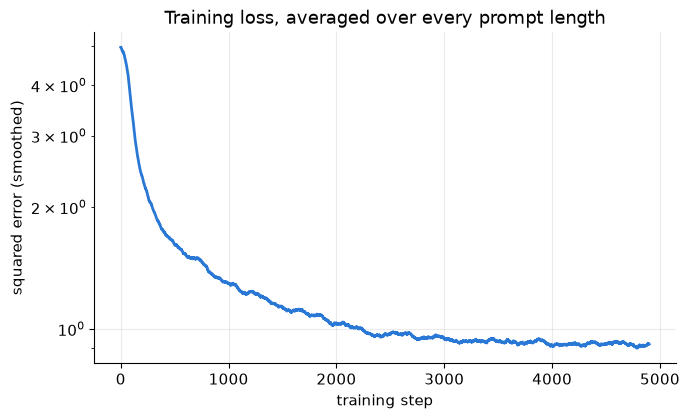

In [4]:
def train(model, steps=5000, lr=1e-3):
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    history, t0 = [], time.time()
    for step in range(1, steps + 1):
        x, y = sample(64)
        loss = ((model(x, y) - y) ** 2).mean()
        opt.zero_grad(); loss.backward(); opt.step()
        history.append(loss.item())
        if step % 1000 == 0:
            print(f"step {step:5d}  loss {np.mean(history[-200:]):.3f}  ({time.time() - t0:.0f}s)")
    return history

if CKPT.exists() and not RETRAIN:
    saved = torch.load(CKPT)
    model.load_state_dict(saved["weights"]); history = saved["history"]
    print(f"loaded the saved model ({len(history)} training steps)")
else:
    history = train(model)
    CKPT.parent.mkdir(exist_ok=True)
    torch.save({"weights": model.state_dict(), "history": history}, CKPT)
model.eval()

smooth = np.convolve(history, np.ones(100) / 100, mode="valid")
plt.plot(smooth, color=SERIES[0], lw=2)
plt.yscale("log"); plt.xlabel("training step"); plt.ylabel("squared error (smoothed)")
plt.title("Training loss, averaged over every prompt length"); plt.show()

The loss levels off near 0.9 rather than falling to zero because it averages over every prompt length, including prompts with 0 to 4 examples, where nobody can predict $y$ well. The next section separates the lengths.

## 5. What algorithm did it learn?

Now the test. For new prompts, compare the transformer's error at each prompt length $k$ with algorithms we understand:

- **Least squares**: the best possible here. Once $k \ge 5$ it recovers $w$ exactly (no noise), so its error drops to zero.
- **One step of gradient descent** from $w = 0$: $\hat w = \eta \sum_i y_i x_i$, with the best possible step size for these inputs, $\eta = 1/(k + d + 1)$. Some studies argue transformers implement steps like this inside their layers. (A naive step of $1/k$ overshoots badly with few examples; the tuned step makes it a fair comparison.)
- **Nearest neighbour**: copy the $y$ of the most similar $x$.
- **Predict zero**: knows nothing (the error of a random guess).

Errors are divided by $D = 5$, so "1.0" means as bad as guessing zero.

In [5]:
@torch.no_grad()
def compare(x, y):
    n, k_max = x.shape[0], x.shape[1] - 1
    out = {"transformer": ((model(x, y) - y) ** 2).mean(0).numpy() / D}
    ls, gd, nn_, zero = [], [], [], []
    for k in range(k_max + 1):
        xq, yq = x[:, k], y[:, k]
        zero.append((yq ** 2).mean().item() / D)
        if k == 0:
            ls.append(zero[-1]); gd.append(zero[-1]); nn_.append(zero[-1]); continue
        X, Y = x[:, :k], y[:, :k]
        w_ls = torch.linalg.pinv(X) @ Y.unsqueeze(-1)                      # least squares (min-norm)
        w_gd = (X.transpose(1, 2) @ Y.unsqueeze(-1)) / (k + D + 1)         # one gradient step, best step size
        near = ((X - xq[:, None]) ** 2).sum(-1).argmin(1)
        ls.append(((xq[:, None] @ w_ls).squeeze() - yq).pow(2).mean().item() / D)
        gd.append(((xq[:, None] @ w_gd).squeeze() - yq).pow(2).mean().item() / D)
        nn_.append((Y[torch.arange(n), near] - yq).pow(2).mean().item() / D)
    out.update({"least squares": np.array(ls), "one gradient step": np.array(gd),
                "nearest neighbour": np.array(nn_), "predict zero": np.array(zero)})
    return out

x_test, y_test = sample(3000)
res = compare(x_test, y_test)
for k in [0, 1, 2, 3, 4, 5, 6, 10, 20]:
    print(f"k = {k:2d}  " + "   ".join(f"{m} {v[k]:.3f}" for m, v in res.items()))

k =  0  transformer 0.960   least squares 0.949   one gradient step 0.949   nearest neighbour 0.949   predict zero 0.949
k =  1  transformer 0.805   least squares 0.793   one gradient step 0.837   nearest neighbour 1.899   predict zero 0.978
k =  2  transformer 0.587   least squares 0.567   one gradient step 0.726   nearest neighbour 1.350   predict zero 0.949
k =  3  transformer 0.448   least squares 0.417   one gradient step 0.685   nearest neighbour 1.171   predict zero 1.013
k =  4  transformer 0.290   least squares 0.201   one gradient step 0.594   nearest neighbour 1.101   predict zero 0.982
k =  5  transformer 0.181   least squares 0.000   one gradient step 0.526   nearest neighbour 0.868   predict zero 0.977
k =  6  transformer 0.127   least squares 0.000   one gradient step 0.505   nearest neighbour 0.855   predict zero 0.982
k = 10  transformer 0.037   least squares 0.000   one gradient step 0.373   nearest neighbour 0.701   predict zero 0.984
k = 20  transformer 0.010   leas

> ⏸️ **Pause and predict:** before you plot it, where do you expect the transformer's curve to sit, relative to least squares and one gradient step, at $k = 3$ and at $k = 10$?

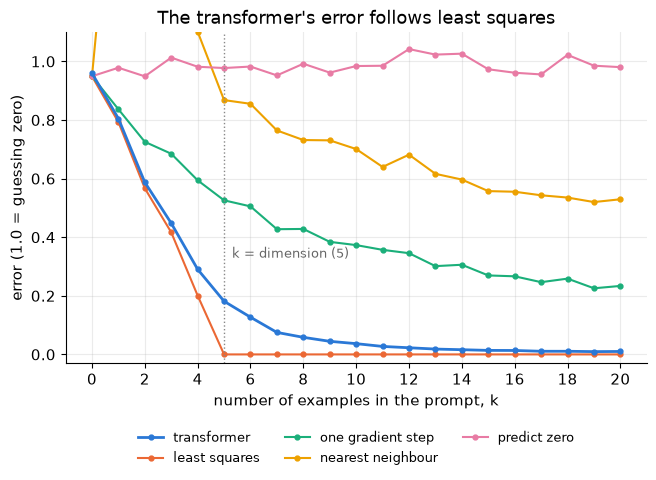

In [6]:
fig, ax = plt.subplots()
for (name, v), c in zip(res.items(), SERIES):
    ax.plot(range(len(v)), v, "-o", ms=3.5, lw=2 if name == "transformer" else 1.5, color=c,
            label=name, zorder=3 if name == "transformer" else 2)
ax.axvline(D, color="#888", ls=":", lw=1)
ax.text(D + 0.3, 0.33, "k = dimension (5)", color="#666", fontsize=9)
ax.set_xticks(range(0, K + 1, 2))
ax.set(xlabel="number of examples in the prompt, k", ylabel="error (1.0 = guessing zero)",
       title="The transformer's error follows least squares", ylim=(-0.03, 1.1))
ax.legend(frameon=False, fontsize=9, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.17)); plt.show()

**What just happened.** With no weight changes, the transformer's error falls as the prompt holds more examples. For $k < 5$ it tracks **least squares** closely, the best any learner can do with that little information, and it beats both one gradient step and nearest neighbour. After $k = 5$, least squares becomes exact and the transformer approaches it without quite reaching zero (more training narrows the gap). Training on many small tasks produced a model whose forward pass *is* a regression algorithm.

**Sanity check against a known answer:** least squares really is exact once $k \ge 5$, as theory says (its error above is about 0.000).

## 6. Is it really reading the examples?

A sceptic might say it's just predicting something typical. Test it: keep each prompt's $x$ values, but **shuffle the $y$ values among the examples**. That keeps every number it sees the same, but breaks the link between each $x$ and its $y$. If the model is learning from the pairs, its error should jump back up.

In [7]:
x_s, y_s = x_test.clone(), y_test.clone()
k = 10
perm = torch.randperm(k)
y_s[:, :k] = y_s[:, perm]                                 # scramble which y goes with which x
with torch.no_grad():
    e_real = ((model(x_test, y_test)[:, k] - y_test[:, k]) ** 2).mean().item() / D
    e_scr = ((model(x_s, y_s)[:, k] - y_s[:, k]) ** 2).mean().item() / D
print(f"error at k = {k} with the real pairs:      {e_real:.3f}")
print(f"error at k = {k} with the y's scrambled:   {e_scr:.3f}")

error at k = 10 with the real pairs:      0.037
error at k = 10 with the y's scrambled:   1.831


**What just happened.** Scrambling the pairs makes the model much worse, even though every number in the prompt is unchanged. Its predictions depend on *which* $y$ goes with *which* $x$, which is the definition of learning from the examples.

## 7. Where in-context learning breaks

Least squares works for any inputs. The transformer only ever saw $x \sim \mathcal{N}(0, I)$. What happens if the inputs are 3 times larger?

In [8]:
x_big, y_big = sample(3000, x_scale=3.0)
res_big = compare(x_big, y_big)
for k in [5, 10, 20]:
    print(f"k = {k:2d}   transformer {res_big['transformer'][k]:.2f}   least squares {res_big['least squares'][k]:.2f}"
          f"   (normal-sized inputs: transformer {res['transformer'][k]:.2f})")

k =  5   transformer 2.75   least squares 0.00   (normal-sized inputs: transformer 0.18)
k = 10   transformer 1.47   least squares 0.00   (normal-sized inputs: transformer 0.04)
k = 20   transformer 1.00   least squares 0.00   (normal-sized inputs: transformer 0.01)


**What just happened.** On bigger inputs the transformer falls apart while least squares stays exact. The model didn't learn *least squares*; it learned something that **behaves like** least squares on the kind of data it was trained on. This is the central caveat of in-context learning, small or large: it's as general as the task distribution behind it, and no more. Keep it in mind for Part 1b (what does Claude's training distribution make easy?) and Part 2 (a model pretrained on *synthetic* tables, pointed at real biology).

## Recap

| Idea | What we saw |
|---|---|
| In-context learning | Error fell as the prompt grew, with the weights frozen |
| Learning a learning algorithm | Trained on many random tasks, the model's forward pass behaves like regression |
| Comparing with known algorithms | Close to least squares below $k = 5$; better than one gradient step and nearest neighbour |
| Using the examples | Scrambling the (x, y) pairs destroyed its accuracy |
| Limits | Inputs 3x larger than in training: it failed, least squares didn't |

## Try it yourself

1. **Add noise** to the training targets ($y = w \cdot x + \epsilon$). Does the model start to behave like *ridge* regression, shrinking its estimates, rather than least squares?
2. **Train longer** (set `RETRAIN = True` and raise `steps`). How close to zero does the error after $k = 5$ get?
3. **Change the task family**: make $w$ sparse (only one non-zero entry). Does the model learn to need fewer examples than least squares?
4. **Connect to the gradient-descent tutorial**: plot the error of 2, 3 and 5 gradient steps. How many steps does the transformer resemble?